In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Original Dataset:")
print(df.head())

print("\nStatistical Summary:")
print(df.describe())

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors.csv
Original Dataset:
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

In [3]:
numeric_df = df.select_dtypes(include=np.number).copy()

numeric_df = numeric_df.fillna(numeric_df.median())

print("Numerical Dataset:")
print(numeric_df.head())

print("\nNumber of Features:", numeric_df.shape[1])

Numerical Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0             23          84            7               73                  0   
1             19          64            8               59                  2   
2             24          98            7               91                  2   
3             29          89            8               98                  1   
4             19          92            6               65                  3   

   Physical_Activity  Exam_Score  
0                  3          67  
1                  4          61  
2                  4          74  
3                  4          71  
4                  4          70  

Number of Features: 7


In [4]:
scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(numeric_df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)

print("Normalized Dataset:")
print(normalized_df.head().round(2))

print("\nMinimum Values:")
print(normalized_df.min().round(2))

print("\nMaximum Values:")
print(normalized_df.max().round(2))

Normalized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.51        0.60         0.50             0.46               0.00   
1           0.42        0.10         0.67             0.18               0.25   
2           0.53        0.95         0.50             0.82               0.25   
3           0.65        0.73         0.67             0.96               0.12   
4           0.42        0.80         0.33             0.30               0.38   

   Physical_Activity  Exam_Score  
0               0.50        0.26  
1               0.67        0.13  
2               0.67        0.41  
3               0.67        0.35  
4               0.67        0.33  

Minimum Values:
Hours_Studied        0.0
Attendance           0.0
Sleep_Hours          0.0
Previous_Scores      0.0
Tutoring_Sessions    0.0
Physical_Activity    0.0
Exam_Score           0.0
dtype: float64

Maximum Values:
Hours_Studied        1.0
Attendance           1.0
Sleep_Hou

In [5]:
scaler = StandardScaler()

standardized_data = scaler.fit_transform(numeric_df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_df.columns
)

print("Standardized Dataset:")
print(standardized_df.head().round(2))

print("\nMean of Each Feature:")
print(standardized_df.mean().round(2))

print("\nStandard Deviation of Each Feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Dataset:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0           0.50        0.35        -0.02            -0.14              -1.21   
1          -0.16       -1.38         0.66            -1.12               0.41   
2           0.67        1.56        -0.02             1.11               0.41   
3           1.51        0.78         0.66             1.59              -0.40   
4          -0.16        1.04        -0.70            -0.70               1.22   

   Physical_Activity  Exam_Score  
0               0.03       -0.06  
1               1.00       -1.60  
2               1.00        1.74  
3               1.00        0.97  
4               1.00        0.71  

Mean of Each Feature:
Hours_Studied       -0.0
Attendance          -0.0
Sleep_Hours         -0.0
Previous_Scores      0.0
Tutoring_Sessions    0.0
Physical_Activity   -0.0
Exam_Score          -0.0
dtype: float64

Standard Deviation of Each Feature:
Hours_Studied        1.0
Attend

PCA Transformed Dataset:
    PC1   PC2
0  0.15  0.59
1 -2.06 -0.19
2  2.59  0.04
3  1.91  1.56
4  1.09 -1.61

Explained Variance Ratio:
[0.25214912 0.1499744 ]

Total Variance Retained:
0.4021235201240285


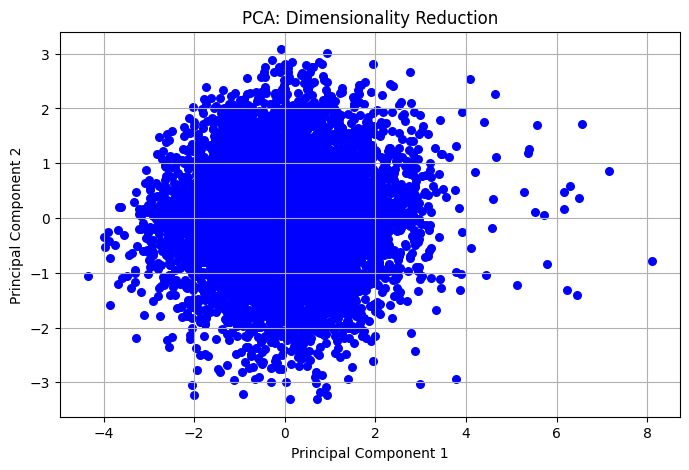

In [6]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Dataset:")
print(pca_df.head().round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 5))
plt.scatter(pca_df['PC1'], pca_df['PC2'], color='blue', s=30)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()